In [1]:
%matplotlib inline
# %matplotlib qt
import astropy.units as u
import numpy as np
import os
import yaml
import scipy
import glob
import scipy.stats
import matplotlib.pyplot as plt
from spysii.sim_run import SimulateSiiRuns
from astropy.time import Time
import matplotlib
from astropy.coordinates import SkyCoord

Found star with c.SkyCoord.from_name
<SkyCoord (ICRS): (ra, dec) in deg
    (183.95154504, -17.54193046)>
Closest star found within the JMDC is:
 -Star ids: HD106625 or GAM CRV
- Stellar diameter: 0.72


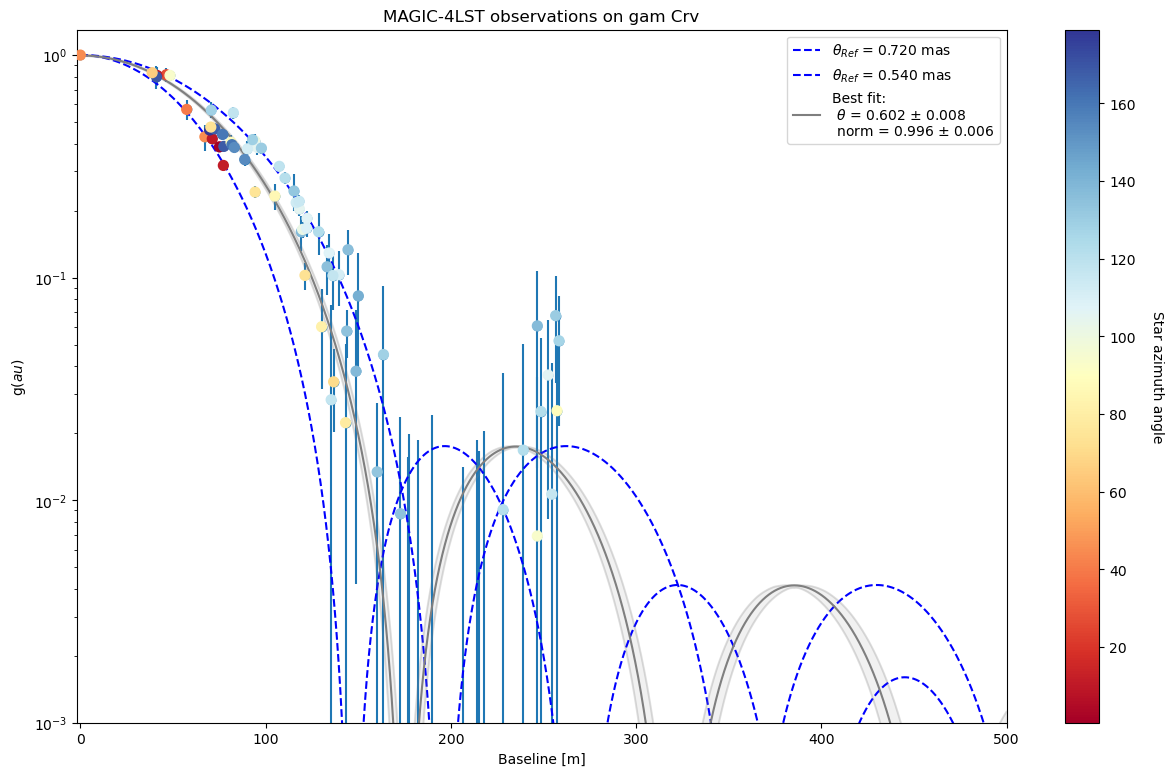

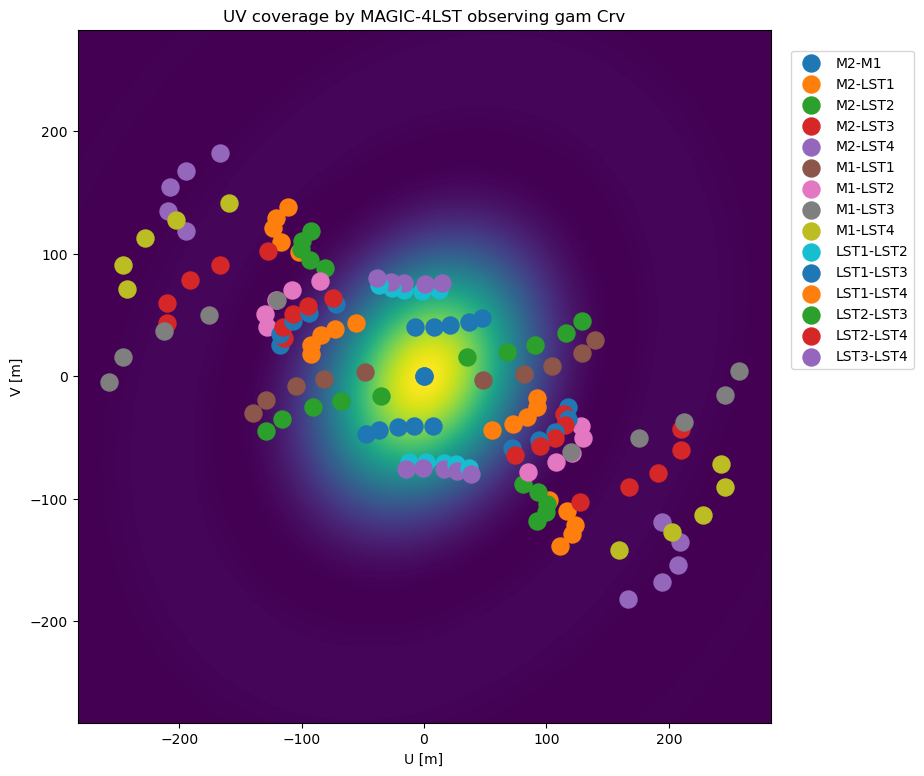

In [2]:
sim_run = SimulateSiiRuns("gam Crv", semi_major_axis_orientation=0.5, 
                          compression_factor=0.75,
                          observatory_name="MAGIC-4LST")

times = [
    '2021-05-14T22:00:00',
         '2021-05-14T23:00:00',
         '2021-05-15T00:10:00',
         '2021-05-15T01:00:00', 
         '2021-05-15T02:00:00', 
]

time_array = Time(times, format='isot', scale='utc')

sim_run.simulate_observations(time_array, 
                              run_duration=20*u.min, 
                              # ignore_larger_baselines=250., 
                              fast_simulation=True,
                             )
sim_run.add_zbc_measurement(1., 0.002, "Combined")

# sim_run.simulate_zbc_observations(time_array, run_duration=10*u.min)

# sim_run.plot_v2(set_log_yscale=True)
sim_run.fit_uniform_disc()
sim_run.plot_v2(set_log_yscale=True)
fit_results = sim_run.uniform_disc_fit
fit_results['theta_e']/fit_results['theta']
sim_run.f.get_axes()[0].set_xlim([0, 400])

sim_run.f
sim_run.plot_uv()

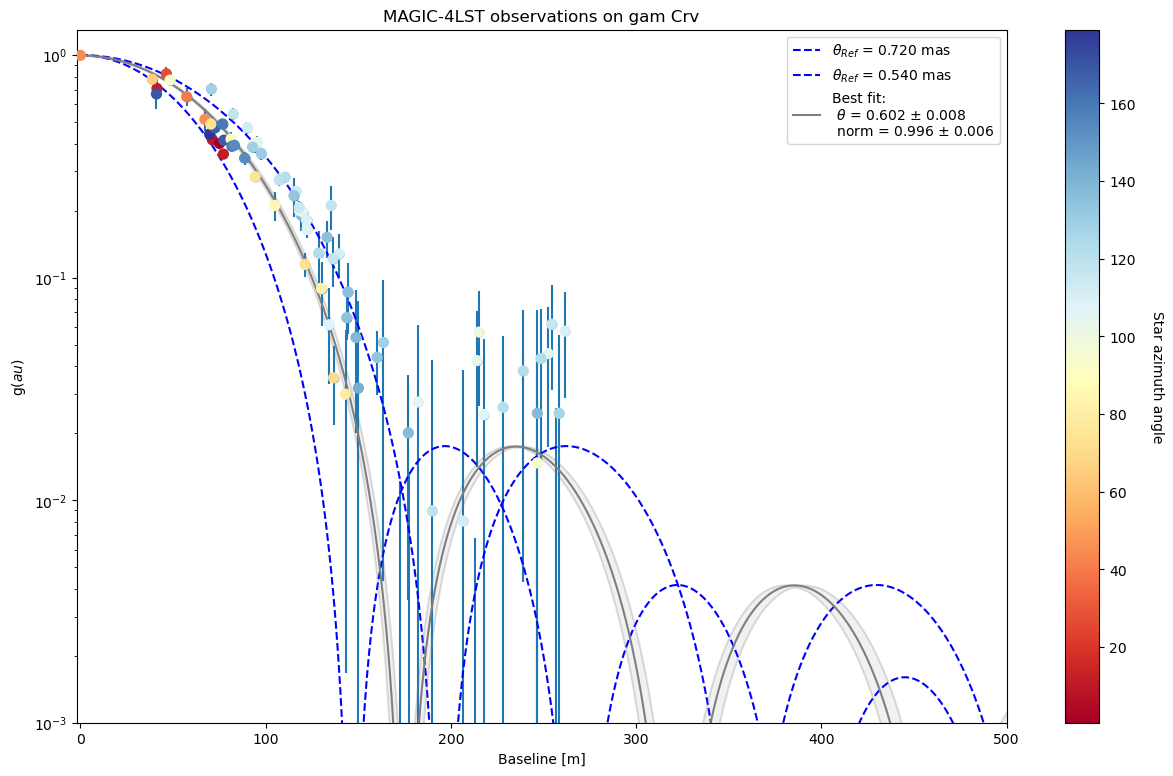

In [3]:
sim_run.randomize_simulation()
sim_run.plot_v2()

Found star with c.SkyCoord.from_name
<SkyCoord (ICRS): (ra, dec) in deg
    (183.95154504, -17.54193046)>
Closest star found within the JMDC is:
 -Star ids: HD106625 or GAM CRV
- Stellar diameter: 0.72


ERROR:root:The altitude of the source at the time 2021-05-15T03:00:00.000 is just too low.
ERROR:root:The altitude of the source at the time 2021-05-15T04:00:00.000 is just too low.


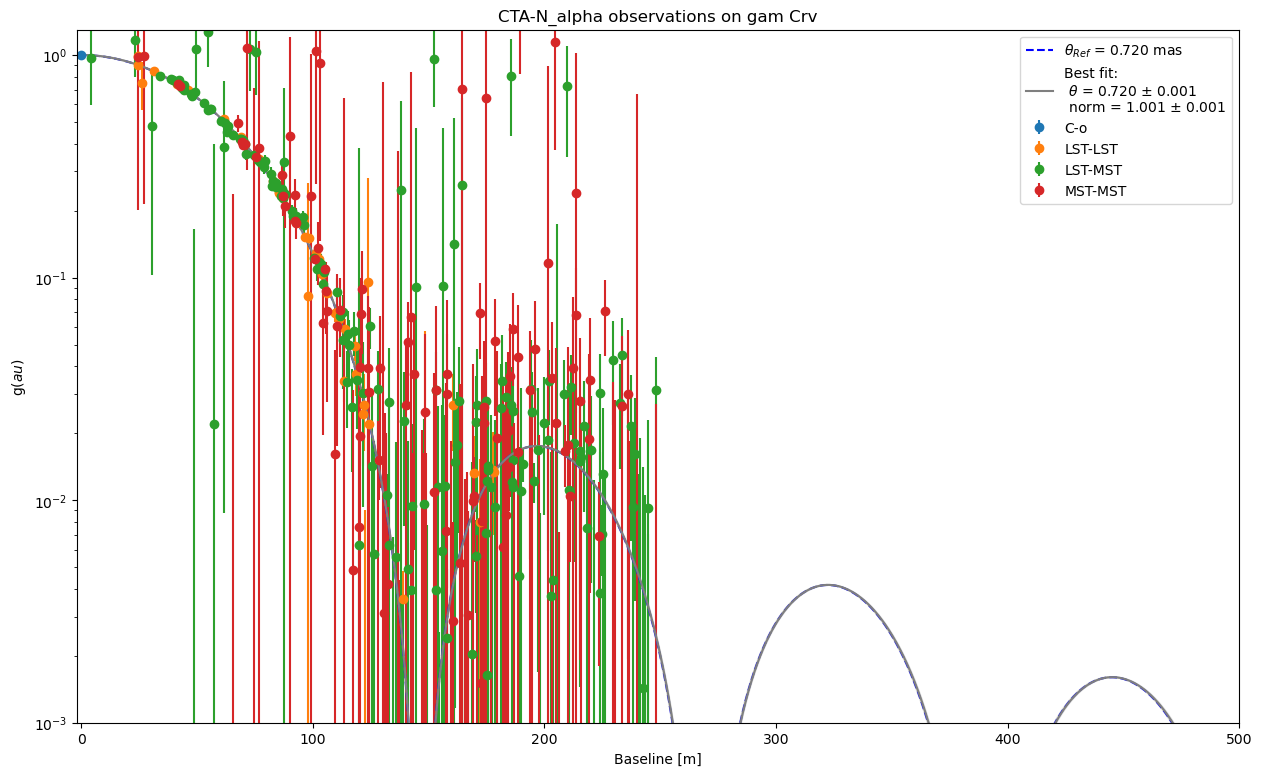

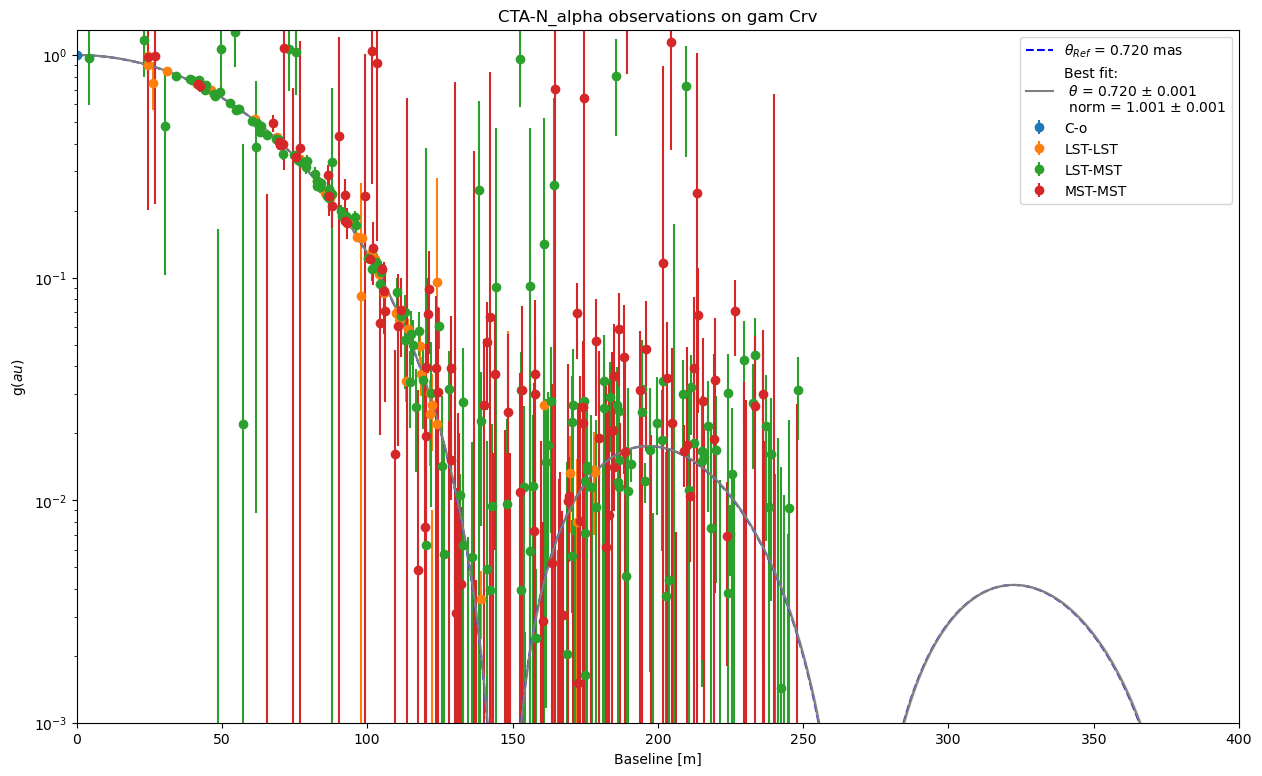

In [4]:
sim_run = SimulateSiiRuns("gam Crv", observatory_name="CTA-N_alpha")

times = ['2021-05-14T22:00:00',
         '2021-05-14T23:00:00',
         '2021-05-15T00:10:00',
         '2021-05-15T01:00:00', 
         '2021-05-15T02:00:00', 
         '2021-05-15T03:00:00', 
         '2021-05-15T04:00:00']

# times = ['2021-02-12T00:00:00',
#          '2021-02-12T00:45:00',
#          '2021-02-12T01:30:00',
#          '2021-02-12T03:00:00', 
#          '2021-02-12T04:30:00', 
#          '2021-02-12T06:00:00', 
#          '2021-02-12T07:30:00']
time_array = Time(times, format='isot', scale='utc')
#zbc_times = ['2021-06-16T01:30:00', 
#             '2021-06-16T02:30:00']
#zbc_time_array = Time(zbc_times, format='isot', scale='utc')

sim_run.simulate_observations(time_array, run_duration=20*u.min, 
                              ignore_larger_baselines=250., 
                              fast_simulation=True
                             )
sim_run.add_zbc_measurement(1., 0.002, "Combined")

# sim_run.simulate_zbc_observations(time_array, run_duration=10*u.min)

# sim_run.plot_v2(set_log_yscale=True)
sim_run.fit_uniform_disc()
sim_run.plot_v2(set_log_yscale=True)
fit_results = sim_run.uniform_disc_fit
fit_results['theta_e']/fit_results['theta']
sim_run.f.get_axes()[0].set_xlim([0, 400])
# sim_run.f.legend().set_bbox_to_anchor = (1.3, 1.00)
# sim_run.f.legend().set_loc='bottom left'
sim_run.f